# Location extraction: source and test domain analysis

This notebook asks how different the competition texts are from the Ukrainian and Russian training corpora. It uses descriptive features and a small character GRU classifier, matching the assignment's recurrent model family. A domain classifier detects source differences; it does not measure location extraction quality.

Run the data audit notebook first. The local `output/` files are excluded from Git.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent.parent
elif PROJECT.name == 'eda':
    PROJECT = PROJECT.parent
HERE = PROJECT / 'eda'
sys.path.insert(0, str(PROJECT))
from eda.core.analysis import OUTPUT, SEED
from eda.core.adversarial import run_both

audit = json.loads((OUTPUT / 'audit.json').read_text(encoding='utf-8'))
RESULT_FILE = OUTPUT / 'adversarial.json'
if not RESULT_FILE.exists():
    run_both()
result = json.loads(RESULT_FILE.read_text(encoding='utf-8'))
print('Seed:', SEED, '; source sample: 477 per corpus; test: 477')

Seed: 3012026 ; source sample: 477 per corpus; test: 477


## Descriptive differences

The source figures use deterministic bounded samples from the full audit; all 477 test texts are included. Means can hide long tails, so compare the distribution too.

,source,n,characters,words,newlines,urls,emoji,uk_chars,ru_chars,digits,newline %,URL %,emoji %
0,uk,4000,101.84,17.98,0.00,0.00,0.0,6.20,0.00,0.78,0.00,0.00,0.02
1,ru,6000,119.35,20.02,0.00,0.00,0.0,0.00,2.00,1.35,0.00,0.05,0.00
2,test,477,395.41,69.56,5.17,0.04,0.6,21.64,0.31,5.31,85.12,3.98,60.17


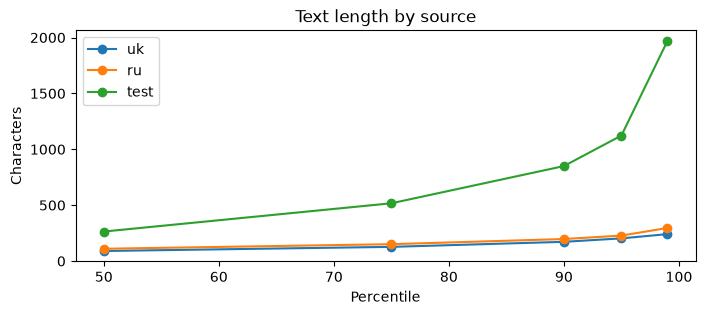

In [2]:
features = ('characters','words','newlines','urls','emoji','uk_chars','ru_chars','digits')
rows = []
for source, records in [('uk',audit['uk']['sample']),('ru',audit['ru']['sample']),('test',audit['test']['rows'])]:
    rows.append({'source': source, 'n': len(records),
                 **{f: np.mean([r[f] for r in records]) for f in features},
                 'newline %': 100*np.mean([r['newlines']>0 for r in records]),
                 'URL %': 100*np.mean([r['urls']>0 for r in records]),
                 'emoji %': 100*np.mean([r['emoji']>0 for r in records])})
display(pd.DataFrame(rows).round(2))
fig, ax = plt.subplots(figsize=(8,3))
for source, records in [('uk',audit['uk']['sample']),('ru',audit['ru']['sample']),('test',audit['test']['rows'])]:
    ax.plot([50,75,90,95,99], np.percentile([r['characters'] for r in records],[50,75,90,95,99]), marker='o', label=source)
ax.set(xlabel='Percentile', ylabel='Characters', title='Text length by source')
ax.legend(); plt.show()

## GRU adversarial validation

For each source corpus, sample 477 distinct source groups and pair them with 477 competition texts. Train on 75% of each class and score on the remaining 25%. Russian source rows are selected from distinct documents; Ukrainian rows have distinct texts. The character vocabulary is learned from training rows only. AUC of 0.5 means no discrimination; larger values indicate easier separation. The interval below resamples held-out texts and does not account for training variability.

,source vs test,train per class,held out per class,AUC,AUC 95% interval,balanced accuracy
0,uk,357,120,0.914,"(0.869, 0.953)",0.904
1,ru,357,120,0.979,"(0.963, 0.993)",0.938


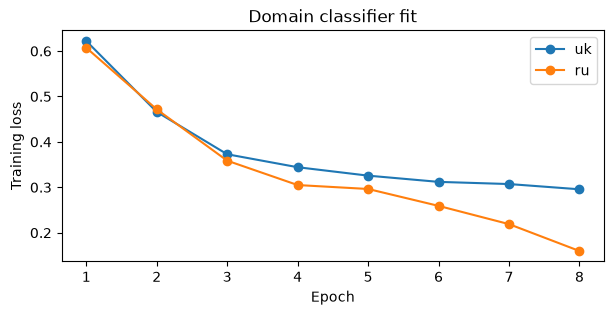

In [3]:
display(pd.DataFrame([{'source vs test': s, 'train per class': r['train_per_class'],
                       'held out per class': r['holdout_per_class'], 'AUC': r['auc'],
                       'AUC 95% interval': tuple(round(x,3) for x in r['auc_interval_95']),
                       'balanced accuracy': r['balanced_accuracy']}
                      for s,r in result.items()]).round(3))
fig,ax = plt.subplots(figsize=(7,3))
for source,r in result.items():
    ax.plot(range(1,len(r['train_loss_by_epoch'])+1), r['train_loss_by_epoch'], marker='o', label=source)
ax.set(xlabel='Epoch', ylabel='Training loss', title='Domain classifier fit')
ax.legend(); plt.show()

The held-out GRU AUC is 0.914 for Ukrainian versus test and 0.979 for Russian versus test. These values support a strong source-style difference, even after truncating texts to 256 characters. The uncertainty intervals describe only the held-out sample for each fitted model; they do not measure variation from new training runs.

In [4]:
for source,r in result.items():
    inspection = pd.DataFrame({'truth': r['holdout_labels'], 'p(test)': r['holdout_probabilities'],
                               'text': [t[:180].replace('\n',' ↵ ') for t in r['holdout_texts']]})
    print(source.upper(), 'source texts most like test')
    display(inspection[inspection['truth']==0].nlargest(3,'p(test)'))
    print(source.upper(), 'test texts most like source')
    display(inspection[inspection['truth']==1].nsmallest(3,'p(test)'))

UK source texts most like test


,truth,p(test),text
42,0,0.713382,То пощо було його в Ригу відряджати на навчанн...
111,0,0.591735,"Ах, а як сердечно і гаряче цілував він її паль..."
27,0,0.552716,У 2019 році Державна підтримка галузі тваринни...


UK test texts most like source


,truth,p(test),text
162,1,0.083921,‼️Росіяни запустили фейк про вивезення ікон з ...
230,1,0.089684,❗Поліція Києва отримала повідомлення про замін...
181,1,0.091592,✍️ У Києві пропонують перейменувати вулицю на ...


RU source texts most like test


,truth,p(test),text
75,0,0.983489,"Об этом сообщает агентство ""Интерфакс"" со ссыл..."
113,0,0.943202,Следственный комитет РФ намерен предъявить обв...
34,0,0.926430,Между тем анонимный сотрудник израильского МИД...


RU test texts most like source


,truth,p(test),text
164,1,0.026237,Приват24 этой ночью не будет работать ↵ ↵ 3 0...
237,1,0.047729,С 1 сентября 2023 года ПЦУ и УГКЦ переходят на...
120,1,0.057076,"👂Виталик, люди с Сырца устали ждать горячую во..."


## What this means for model selection

If the GRU reliably distinguishes sources, source-only validation may overstate competition performance. Compare source-specific slices and use the 26 separate labeled examples in `labeling_sample.csv` for qualitative error analysis. Do not tune repeatedly on those 26 examples. Consider corpus mixing, character or BPE coverage, and realistic text length when selecting a recurrent model. Domain AUC cannot determine which training mixture or NER model will score best; that requires frozen validation and later leaderboard evidence.

## Controlled domain comparison

The original source-versus-test classifier is repeated with fixed group membership and three seeds. A length-matched subset pairs 160 source and test texts per source by character length (the selector permits gaps up to 15 characters; observed gaps are reported below). A further diagnostic copy masks newline, URL, and emoji cues. Membership is unchanged across conditions; only model inputs change. The 40 held-out texts per class in the matched run support a diagnostic, not a precise estimate for all competition posts.

In [5]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
control_output=HERE / 'output'
controls=json.loads((control_output / 'domain_controls.json').read_text())
display(pd.DataFrame(controls['sizes']))
control_results=pd.DataFrame(controls['results'])
display(control_results.pivot_table(index=['source','seed'],columns='condition',values='auc').round(3))
display(control_results.groupby(['source','condition']).auc.agg(['mean','min','max']).round(3))

,source,full_per_class,matched_per_class,matched_source_mean_length,matched_test_mean_length,matched_mean_absolute_length_gap
0,uk,400,160,124.7375,124.7375,0.0
1,ru,400,160,124.7375,124.7375,0.0


condition        full  length_matched  length_matched_cues_masked
source seed                                                      
ru     3012026  0.953           0.879                       0.920
       3012027  0.927           0.923                       0.948
       3012028  0.960           0.946                       0.938
uk     3012026  0.887           0.812                       0.805
       3012027  0.873           0.838                       0.814
       3012028  0.868           0.820                       0.828

mean    min    max
source condition                                      
ru     full                        0.947  0.927  0.960
       length_matched              0.916  0.879  0.946
       length_matched_cues_masked  0.935  0.920  0.948
uk     full                        0.876  0.868  0.887
       length_matched              0.823  0.812  0.838
       length_matched_cues_masked  0.816  0.805  0.828

Length matching lowers mean AUC from 0.876 to 0.823 for Ukrainian and from 0.947 to 0.916 for Russian. After cue masking on the matched rows, mean AUC is 0.816 and 0.935, respectively. The Russian increase after masking and the variation across three seeds show that the named cues do not explain the remaining separation in a stable, one-directional way. Matched texts were selected from the shorter competition posts, so these results do not describe the full test distribution. Domain AUC remains a diagnostic of source differences, not a measure of location extraction performance.

## Word BiGRU confirmation

The earlier domain classifier used characters, while the extractor uses word tokens and a bidirectional GRU. This bounded check uses the extractor's embedding size and encoder width with a binary document head. It trains on the same length-matched source/test partitions, after masking URLs, emoji, and line breaks. The test text is used only for domain discrimination; its hidden location labels are never used.

In [6]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
root = Path.cwd()
if root.name == 'notebooks': root = root.parent.parent
elif root.name == 'eda': root = root.parent
comparison = json.loads((root / 'eda/output/eda_comparison/domain_word_bigru.json').read_text())
rows = [{'source': item['source'], 'seed': item['seed'], 'AUC': item['auc'],
         'group_bootstrap_95': item['group_bootstrap_95'],
         'heldout_per_class': item['heldout_per_class']}
        for item in comparison['results']]
display(pd.DataFrame(rows).round(3))

,source,seed,AUC,group_bootstrap_95,heldout_per_class
0,uk,3012026,0.734,"[0.612766, 0.831875]",40
1,uk,3012027,0.819,"[0.724969, 0.905062]",40
2,uk,3012028,0.873,"[0.787797, 0.945656]",40
3,ru,3012026,0.978,"[0.947469, 0.99625]",40
4,ru,3012027,0.894,"[0.811219, 0.9625]",40
5,ru,3012028,0.992,"[0.975297, 1.0]",40


In [7]:
cues = json.loads((root / 'eda/output/eda_comparison/domain_cue_baselines.json').read_text())
display(pd.DataFrame(cues['results'])[['source', 'seed', 'bigru_auc',
                                        'ukrainian_letter_auc', 'length_auc']].round(3))

,source,seed,bigru_auc,ukrainian_letter_auc,length_auc
0,uk,3012026,0.734,0.450,0.416
1,uk,3012027,0.819,0.450,0.416
2,uk,3012028,0.873,0.450,0.416
3,ru,3012026,0.978,0.938,0.427
4,ru,3012027,0.894,0.938,0.427
5,ru,3012028,0.992,0.938,0.427


The word BiGRU distinguishes both source corpora from competition text despite length matching and cue masking. Ukrainian AUC ranges from 0.734 to 0.873 across seeds; Russian AUC ranges from 0.894 to 0.992. The Russian result is largely explained by language: a single Ukrainian-letter indicator reaches AUC 0.938 on those same held-out rows. For the Ukrainian source, that indicator has AUC 0.450 while the BiGRU remains substantially above chance. Masked text length alone has AUC 0.416–0.427, indicating a smaller, reversed length signal. Forty held-out texts per class and the seed spread limit precision. Domain AUC does not predict location-extraction F1.

## Word BiLSTM: experiment protocol

Status: completed. The protocol below was fixed before training; results follow. The assignment (page 2) asks for adversarial validation with the same model as the main task. Word BiLSTM is the leading mixed-language extractor in the bounded comparison (pooled F1 0.646). Use its encoder architecture for this check; final architecture selection still belongs to the next stage.

### Question and model

Can the word BiLSTM distinguish source sentences from competition posts, and does separation remain after controlling for length and obvious formatting cues?

Use the extractor's word tokenizer design, random 96-dimensional embeddings, one bidirectional LSTM with 96 hidden units per direction, and dropout 0.15. Replace the token-level BIO head with one binary head on the concatenated final forward/backward hidden states. For LSTM, use hidden states `h_n`, not cell states `c_n`. Train from scratch to predict source=0 or competition=1. This adapts the same encoder architecture to a different target; it does not reuse the extractor checkpoint or measure its location predictions.

### Bounded experiment

| Condition | Data per source comparison | Purpose |
| --- | --- | --- |
| Primary paired control | Existing 160 source and 160 competition texts, length matched and cue masked; 120 per class train, 40 held out | Compare BiLSTM directly with the saved word BiGRU under the same conditions |
| Broader-text diagnostic | Existing unmasked selection of 400 source and 400 competition texts; 300 per class train, 100 held out | Check the chosen architecture on a broader range of posts, including the obvious domain differences |

Run Ukrainian versus competition and Russian versus competition separately, with seeds 3012026, 3012027, and 3012028. This is six primary fits plus six broader-text fits, twelve new BiLSTM fits in total. Start with the primary control. Reuse valid saved BiGRU results for that condition. The earlier character-GRU results are historical context, not a controlled architecture comparison.

The broader-text and matched conditions use different samples and training sizes. Their AUC difference cannot be attributed solely to length or masking. A separate unmasked matched condition is outside this bounded addition.

### Freeze inputs before training

1. Save exact row IDs, domain labels, split membership, group IDs, preprocessing settings, and input hashes. Match the primary holdout IDs to the saved BiGRU predictions.
2. Audit full accepted source duplicate groups as well as Russian document IDs, exact texts, and normalized competition templates across train/holdout. The existing selector deduplicates documents/texts but does not itself prove separation of all accepted duplicate groups. If this audit fails, freeze corrected partitions and rerun both architectures for the primary comparison; do not compare changed rows with the old GRU scores.
3. Fit the word vocabulary only on domain-training text, up to 16,000 entries. Reuse the same token IDs for paired GRU/LSTM comparisons. This vocabulary includes training competition texts because origin is the target here. It remains separate from all extractor vocabularies.
4. Exclude final local evaluation rows and the 26 labeled qualitative examples. No competition location labels are needed. Preserve original texts and transform only diagnostic inputs.
5. For the primary comparison, retain the existing first-256-token policy. Record truncation, unknown-token rates, empty inputs, and length distributions separately by class and split. Use the same policy for the broader diagnostic and explicitly report how much of long posts is omitted. This is a text-prefix classifier, not a validation of full-post extraction or the extractor's window merging.

### Training and implementation

Use six epochs, batch size 32, AdamW with learning rate 0.003 and weight decay 0.01, binary cross-entropy with logits, and gradient clipping at 1.0, matching the existing word-domain GRU. Evaluate epoch six without choosing a checkpoint or threshold from the holdout. Save training loss and accuracy by epoch; holdout probabilities are the final evidence. Keep the existing GRU artifact unchanged.

Extend `eda/workflows/domain_recurrent_control.py` with a small encoder choice and shared data preparation, training, and scoring. Handle the GRU and LSTM state outputs explicitly. Avoid separate copies of the experiment pipeline. Record architecture, parameter count, tokenizer hash, seeds, software versions, training time, and prediction IDs. Equal width is not equal parameter count; the same seed does not give identical random weights or necessarily identical minibatch order across architectures. Record batch order or use a dedicated shuffle generator for new runs, and describe any difference from the historical GRU.

Time the first fit before scheduling the batch. Use the existing Colab workflow if local runtime would be lengthy; do not start an unbounded local run. For Colab training, check at five-minute intervals and save after each fit. Store new outputs under `eda/output/eda_comparison/domain_word_bilstm/` with an explicit protocol version. Do not overwrite prior results or expand the experiment to maximize AUC.

### Results to add here

- One table: language, condition, seed, train/holdout counts, AUC, and balanced accuracy at a fixed 0.5 threshold. Add the three-seed mean and range without treating seeds as independent held-out samples.
- For the primary control, pair BiLSTM and word BiGRU probabilities by row ID. Report AUC differences per seed and 95% intervals from 1,000 paired resamples of held-out groups, stratified by domain class. These intervals condition on the fitted models and omit training-sample uncertainty.
- Keep the Ukrainian-letter and masked-length baselines on the same primary holdout. Recompute simple cue baselines for the broader selection rather than reusing numbers from different rows.
- Show a compact training-loss plot and a fixed qualitative selection: source texts most like competition, competition texts most like source, and largest GRU/LSTM disagreements. Select at most three examples per category and language, using mean probability across seeds; retain IDs and raw text. Review language, list structure, addresses, footers, and annotation-style differences without claiming classifier explanations from examples alone.

### How to interpret the result

Consistently high BiLSTM AUC supports the warning that source validation may transfer poorly to competition posts. A higher AUC than GRU means the LSTM detects origin more easily; it does not make it a better extractor. Near-chance AUC with poor training fit or wide intervals is inconclusive, not proof that the collections match. A near-chance LSTM result alongside a strong GRU result should first trigger checks of the LSTM state handling, fitting, and input pipeline.

Treat Russian separation cautiously because language alone already separates much of that comparison. Ukrainian separation after matching and masking is more useful evidence of remaining domain differences. The 40-per-class primary holdout and shared membership across seeds limit precision. Neither experiment estimates Kaggle F1 or justifies changing the extraction split automatically.

Finish with a short conclusion on whether the selected architecture confirms the existing domain warning and which examples deserve attention in stage 2. Preserve the source extraction scores and final evaluation reservation. If the final model later changes its tokenizer or encoder substantially, revisit whether this diagnostic still represents it.


## BiLSTM results

The 12 planned BiLSTM fits completed locally on CPU, using two threads. Their training took 88 seconds in total; the first matched fit took less than a second. No extraction model was retrained. The first-256-token policy, train/holdout membership, and vocabulary rules follow the protocol above.

Before pairing results, all six historical word-GRU fits were replayed. Their saved probabilities matched within 1e-6, checking the tokenizer IDs, text order, and shared encoder refactor. Accepted source groups, Russian documents, exact texts, normalized templates, and actual encoded prefixes have no train/holdout overlap. No cross-domain template or encoded-prefix collision was found. The original GRU artifact and original BiLSTM training provenance are preserved; a separate post-run audit records the added encoded-input check and dependency versions.


In [ ]:
bilstm_path = root / 'eda/output/eda_comparison/domain_word_bilstm'
bilstm = json.loads((bilstm_path / 'results.json').read_text())
bilstm_summary = json.loads((bilstm_path / 'summary.json').read_text())
bilstm_selection = json.loads((bilstm_path / 'selection.json').read_text())
columns = ['source', 'condition', 'seed', 'train_per_class', 'heldout_per_class',
           'auc', 'auc_group_bootstrap_95', 'balanced_accuracy_at_0_5']
results_frame = pd.DataFrame(bilstm['runs'])
display(results_frame[columns].round(3))
display(pd.DataFrame(bilstm_summary['summaries']).round(3))


BiLSTM distinguishes the broader source and competition samples: mean AUC is 0.937 for Ukrainian and 0.967 for Russian. Separation remains after matching length and masking cues, with mean AUC 0.839 and 0.934. The Ukrainian controlled result varies substantially across seeds (0.689–0.915); it should not be summarized as a precise single score. The broader and matched samples differ in membership and size, so their difference does not measure the causal effect of masking or text length.

The fixed-threshold balanced accuracy is also reported. AUC ranks examples and can stay high even when the default 0.5 threshold favors one class. We did not tune that threshold against the small holdout.


In [ ]:
paired = results_frame[results_frame.condition == 'matched_masked']
display(paired[['source', 'seed', 'gru_auc', 'auc', 'lstm_minus_gru_auc',
                'paired_difference_95']].round(3))
display(pd.DataFrame(bilstm_summary['cue_baselines']).round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, source in zip(axes, ('uk', 'ru')):
    for run in bilstm['runs']:
        if run['source'] != source:
            continue
        history = run['training']['history']
        ax.plot([v['epoch'] for v in history], [v['loss'] for v in history],
                linestyle='-' if run['condition'] == 'matched_masked' else '--',
                label=f"{run['condition']} / {run['seed']}")
    ax.set(title=source.upper(), xlabel='Epoch', ylabel='Training loss')
axes[-1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()


The controlled LSTM-minus-GRU AUC differences are −0.045, +0.094, and +0.042 for Ukrainian, and −0.036, −0.026, and −0.002 for Russian. This does not establish a consistent LSTM advantage at detecting domain. Bootstrap intervals use the same held-out group draws for both models; seeds share the same holdout and are not independent samples. Architecture size and random minibatch order also differ. The practical finding is that the leading extractor architecture confirms the domain warning.

The Ukrainian-letter baseline remains 0.938 for the Russian controlled comparison, close to the LSTM mean; much of that separation is language. For Ukrainian the letter baseline is 0.450, while the LSTM remains above chance. Raw length alone reaches 0.779 for the broader Ukrainian comparison and 0.719 for Russian. These simple cues explain why broader-post discrimination must not be interpreted as extraction ability.


In [ ]:
input_rows = []
for dataset in bilstm_selection['datasets']:
    for item in dataset['diagnostics']:
        input_rows.append({'source': dataset['source'], 'condition': dataset['condition'], **item})
inputs_frame = pd.DataFrame(input_rows)
display(inputs_frame[inputs_frame.split == 'holdout'][
    ['source', 'condition', 'domain', 'rows', 'tokens_p50_p90_max',
     'truncated_rows', 'omitted_tokens', 'unknown_fraction', 'empty_inputs']].round(3))
examples = pd.DataFrame(bilstm_summary['review_examples'])
examples['excerpt'] = examples.text.str.replace('\n', ' ↵ ', regex=False).str.slice(0, 180)
# Show one example per category/source/condition; all selected raw texts remain in summary.json.
display(examples.groupby(['source', 'condition', 'category'], sort=False).head(1)[
    ['source', 'condition', 'category', 'domain', 'row_id', 'p_competition_mean',
     'gru_p_competition_mean', 'excerpt']].round(3))


### Reading the disagreements

A Ukrainian source sentence about a square on Moldavanka looks competition-like to both controlled models. A competition post reporting two deaths in a Shevchenkivskyi district looks source-like. Both are plausible local-news sentences, showing overlap between the collections despite their overall separation. A short Russian-language competition notice about alcohol-sale hours is also among the broader Russian comparison's source-like examples. These are selected illustrations, not explanations of the models' internal decisions or error-rate estimates.

Some Russian controlled examples called “most source-like” still have competition probability above 0.8. That label means lowest within that class, not necessarily a wrong threshold classification. Retain the probabilities when interpreting the examples.

The unknown-token and truncation table limits the claim: the vocabulary is learned from a few hundred texts, and the broader classifier reads only the first 256 word tokens. It does not validate the extractor's full-post window merging. No final extraction holdout, qualitative location labels, or leaderboard score was used.

For stage 2, keep source scores separate from competition expectations, inspect short news posts and longer structured posts separately, and report language-specific extraction results. High domain AUC supports these checks; it does not supply a correction factor for extraction F1 or justify automatically reweighting source data.
